# Fit a convex effect and inspect its curvature

A constraint should express knowledge about the response mechanism. We use a convex dose response, compare ordinary and convex SCAM-related smooths, and inspect the second derivative that encodes convexity.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nampy.gam import GAM

rng=np.random.default_rng(109)


## Fit ordinary and convex curves

Both fits use P-spline dimension 12 and GCV. Convexity is justified by the simulated mechanism, not chosen after seeing which fitted curve looks more attractive.

In [2]:
x=np.sort(rng.uniform(0,1,240))
data=pd.DataFrame({"x":x,"y":.3+2*(x-.3)**2+rng.normal(0,.2,len(x))})
models={name:GAM(formula=f"y ~ s(x,bs='{basis}',k=12)",smoothing_method="gcv",smoothing_optimizer="bfgs",optimize_smoothing=True).fit(data) for name,basis in [("Ordinary","ps"),("Convex","cx")]}
grid=pd.DataFrame({"x":np.linspace(0,1,180)})

## Inspect the curve and curvature

The derivative display uses training locations supported by the transformed SCAM derivative route. Nonnegative fitted curvature reflects the imposed constraint.

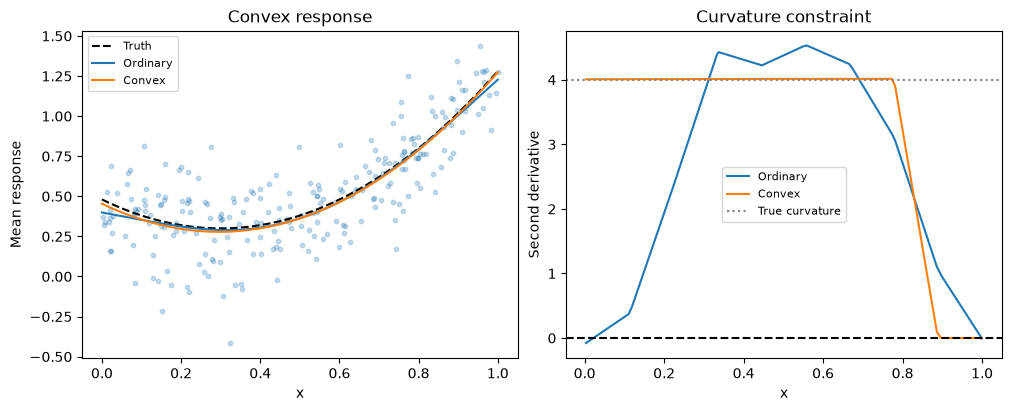

In [3]:
figure,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
axes[0].scatter(data.x,data.y,s=10,alpha=.25)
axes[0].plot(grid.x,.3+2*(grid.x-.3)**2,"k--",label="Truth")
for name,model in models.items():
    axes[0].plot(grid.x,model.predict(grid),label=name)
    derivative=model.derivative(smooth_number=1,deriv=2)
    values=np.asarray(derivative.derivative).reshape(-1)
    axes[1].plot(data.x,values,label=name)
axes[0].set(xlabel="x",ylabel="Mean response",title="Convex response")
axes[1].axhline(0,color="black",linestyle="--")
axes[1].axhline(4,color="grey",linestyle=":",label="True curvature")
axes[1].set(xlabel="x",ylabel="Second derivative",title="Curvature constraint")
for axis in axes:axis.legend(fontsize=8)
plt.show()
plt.close(figure)

The constrained curve maintains nonnegative curvature across the fitted range, whereas the ordinary smooth can turn locally concave. Its curvature need not equal the true value of four. Nonnegative curvature follows from the structural assumption imposed by the basis; the data determine the fitted shape within that restriction and do not independently prove that the true relationship is convex.